### Different meshes are available when solving the diffusion or any other PDE

For a 1D system, the diffusional flux is defined as

$ J = -D \frac{\partial x}{\partial z} $

**Cartesian**

$ \frac{\partial x}{\partial t} = -\frac{\partial}{\partial z} (J) $

**Cylindrical**

$ \frac{\partial x}{\partial t} = - \frac{1}{r} \frac{\partial}{\partial r} (r J) $

**Spherical**

$ \frac{\partial x}{\partial t} = - \frac{1}{r^2} \frac{\partial}{\partial r} (r^2 J) $

To show the different meshes, we could create a simple heat transfer model to apply the meshes to and compare to analytical solutions

In [3]:
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt

from kawin.state_process import ModelState, DifferentialEquationProcess
from kawin.diffusion.mesh.mesh_base import MeshBase, DiffusionPair

@dataclass
class EnthalpyState(ModelState):
    h: np.ndarray

class ThermalModel(DifferentialEquationProcess):
    state_definition: EnthalpyState

    def __init__(self, mesh: MeshBase, k, rho, cp, T0=298.15):
        super().__init__()
        self.mesh = mesh
        self.T0 = 298.15
        self.k = k
        self.rho = rho
        self.cp = cp
        self.D = k / rho / cp

    def enthalpy_to_T(self, h):
        return self.T0+h/self.rho/self.cp

    def T_to_enthalpy(self, T):
        return self.rho*self.cp*(T-self.T0)

    def setup_initial_state_data(self, state: EnthalpyState):
        T = self.mesh.build_response_profile()
        state.h = self.T_to_enthalpy(T)
        return state

    def compute_dxdt(self, state: EnthalpyState):
        h_d, z_d = self.mesh.get_diffusivity_coordinates(state.h)
        h_r, z_r = self.mesh.get_response_coordinates(state.h)
        k_d = self.k*np.ones(h_d.shape)
        T_r = self.enthalpy_to_T(h_r)
        return self.mesh.compute_dxdt([DiffusionPair(diffusivity=k_d, response=T_r)])

    def compute_max_dt(self, state, dxdt):
        return 0.4*self.mesh.dz**2 / self.D / self.mesh.dims

    def apply_dxdt(self, state, dxdt, dt):
        state.h += dxdt*dt

    def finalize(self, state):
        pass

0 0
100 11.865538461538513
200 23.731076923076923
300 35.59661538461538
400 47.46215384615409
500 59.32769230769279
600 71.19323076923106
700 83.05876923076906
800 94.92430769230705
900 106.78984615384505
1000 118.65538461538304
1100 130.52092307692104
1200 142.38646153845903
1300 154.25199999999703
1400 166.11753846153502
1500 177.983076923073
1600 189.848615384611
1700 201.714153846149
1800 213.579692307687
1900 225.445230769225
2000 237.310769230763
2100 249.17630769230098
2200 261.0418461538402
2300 272.90738461538103
2400 284.77292307692187
2500 296.6384615384627
2600 308.50400000000354
2700 320.3695384615444
2800 332.2350769230852
2900 344.10061538462605
3000 355.9661538461669
3100 367.8316923077077
3200 379.69723076924856
3300 391.5627692307894
3400 403.42830769233024
3500 415.2938461538711
3600 427.1593846154119
3700 439.02492307695275
3800 450.8904615384936
3900 462.7560000000344
4000 474.62153846157526
4100 486.4870769231161
4200 498.35261538465693
4300 510.21815384619777
440

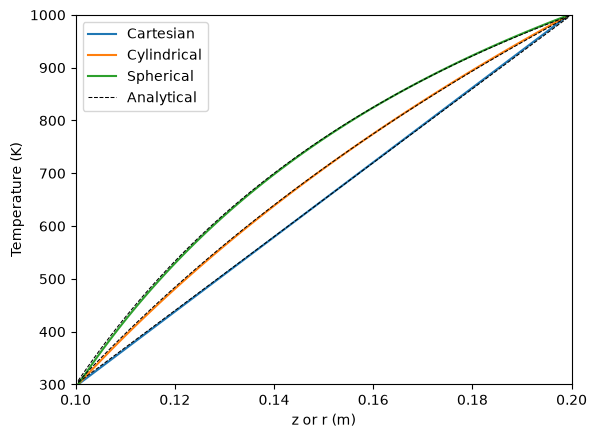

In [7]:
from kawin.diffusion.mesh.fvm import Cartesian1D, Cylindrical1D, Spherical1D
from kawin.diffusion.mesh.mesh_base import ConstantProfile

from kawin.state_process import Solver

xlim = [0.1, 0.2]
ylim = [300, 1000]
N = 100
k = 13 # W/m-K
rho = 7870 # kg/m3
cp = 490 # J/kg-K

mesh_cartesian = Cartesian1D('T', xlim, N)
mesh_cylindrical = Cylindrical1D('T', xlim, N)
mesh_spherical = Spherical1D('T', xlim, N)
meshes = [mesh_cartesian, mesh_cylindrical, mesh_spherical]
labels = ['Cartesian', 'Cylindrical', 'Spherical']
for i, mesh in enumerate(meshes):
    mesh.profile.add_build_step(ConstantProfile(ylim[0]), 'T')
    mesh.set_lbc('T', mesh.DIRICHLET, ylim[0])
    mesh.set_rbc('T', mesh.DIRICHLET, ylim[1])
    model = ThermalModel(mesh, k=k, rho=rho, cp=cp)
    state = model.initialize_state()
    Solver.solve(state, model, 3600)
    plt.plot(mesh.z, model.enthalpy_to_T(state.h), label=labels[i])

# Solution for cartesian: x = A*z + B
# Solution for cylindrical: x = A*ln(r) + B
# Solution for spherical: x = A/r + B
A = (ylim[1] - ylim[0]) / (xlim[1] - xlim[0])
B = ylim[0] - A*xlim[0]
cart_ideal = A*mesh_cartesian.z + B

A = (ylim[1] - ylim[0]) / np.log(xlim[1] / xlim[0])
B = ylim[0] - A*np.log(xlim[0])
cyl_ideal = A*np.log(mesh_cylindrical.z) + B

A = (ylim[1] - ylim[0]) / (1/xlim[1] - 1/xlim[0])
B = ylim[0] - A/xlim[0]
sph_ideal = A/mesh_spherical.z + B
plt.plot(mesh_cartesian.z, cart_ideal, color='k', linestyle='--', linewidth=0.75, label='Analytical')
plt.plot(mesh_cylindrical.z, cyl_ideal, color='k', linestyle='--', linewidth=0.75, label='Analytical')
plt.plot(mesh_spherical.z, sph_ideal, color='k', linestyle='--', linewidth=0.75, label='Analytical')
plt.xlim(xlim)
plt.ylim(ylim)
plt.xlabel('z or r (m)')
plt.ylabel('Temperature (K)')
plt.legend(labels=labels+['Analytical'])
plt.show()

Periodic boundary conditions are also available, but is only valid for cartesian meshes

0 0


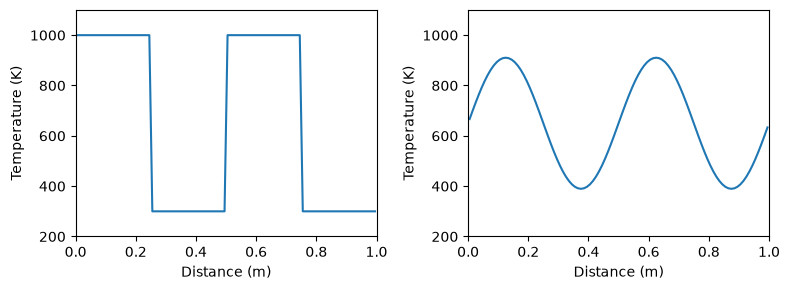

In [9]:
from kawin.diffusion.mesh.mesh_base import BoundedRectangleProfile


mesh = Cartesian1D(responses='T', zlim=[0,1], N=100)
mesh.profile.add_build_step(ConstantProfile(300), 'T')
mesh.profile.add_build_step(BoundedRectangleProfile(0, 0.25, 700, 0), 'T')
mesh.profile.add_build_step(BoundedRectangleProfile(0.5, 0.75, 700, 0), 'T')
mesh.periodic = True

model = ThermalModel(mesh, k=k, rho=rho, cp=cp)
state = model.initialize_state()

fig, ax = plt.subplots(1,2, figsize=(8,3))
ax[0].plot(mesh.z, model.enthalpy_to_T(state.h))
ax[0].set_xlim([0,1])
ax[0].set_ylim([200, 1100])

Solver.solve(state, model, 1000)
ax[1].plot(mesh.z, model.enthalpy_to_T(state.h))

for i in range(2):
    ax[i].set_xlim([0,1])
    ax[i].set_ylim([200, 1100])
    ax[i].set_xlabel('Distance (m)')
    ax[i].set_ylabel('Temperature (K)')
fig.tight_layout()
plt.show()